## Signals and interpolation

Two sines, at 50 Hz and 120 Hz, buried in noise stronger than they are. The magnitude of the FFT shows the two frequencies plainly: with `N` samples at rate `Fs`, bin `k` is the frequency `k*Fs/N`.


found =

    50   120



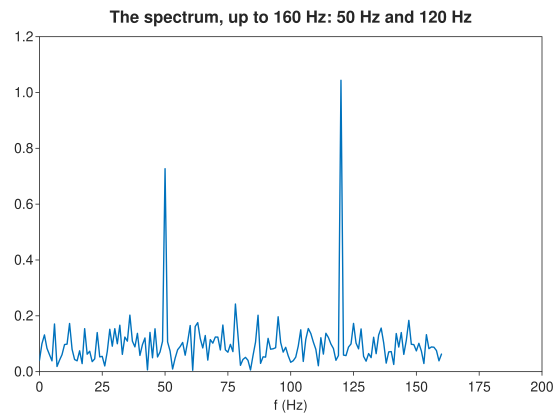

In [ ]:
figure
rng(4);
Fs = 1000; N = 1000; t = (0:N-1) / Fs;
clean = 0.7*sin(2*pi*50*t) + sin(2*pi*120*t);
noisy = clean + 1.5*randn(size(t));
amp = abs(fft(noisy)) / N;  amp = 2*amp(1:161);  freqs = 0:160;
plot(freqs, amp), xlabel('f (Hz)'), title('The spectrum, up to 160 Hz: 50 Hz and 120 Hz')
[~, order] = sort(amp, 'descend');
found = sort(freqs(order(1:2)))

A moving average is a convolution with a short box (`conv`); `filter` applies a recursive filter, here exponential smoothing with $\alpha = 0.1$. Both suppress the noise, and much of the tones with it: at 120 Hz the box keeps about 0.11 of the amplitude and the exponential filter about 0.14, so smoothing distorts this signal, as the distances from the clean signal show.

In [ ]:
rms = @(e) sqrt(mean(e.^2));
averaged = conv(noisy, ones(1, 15) / 15, 'same');
smoothed = filter(0.1, [1, -0.9], noisy);
fprintf('rms distance from the clean signal: noisy %.3f, moving average %.3f, exponential %.3f\n', ...
    rms(noisy - clean), rms(averaged - clean), rms(smoothed - clean))

rms distance from the clean signal: noisy 1.506, moving average 0.938, exponential 0.874


Nine samples of a smooth function, filled in three ways: `'linear'` joins the dots, `'pchip'` keeps the data's shape without overshoot, and `'spline'` is the smoothest, and here the closest.

In [ ]:
xk = 0:8;  yk = sin(xk) .* exp(-xk/6);
xq = linspace(0, 8, 161);  exact = sin(xq) .* exp(-xq/6);
fprintf('largest error: linear %.4f, pchip %.4f, spline %.4f\n', max(abs(interp1(xk, yk, xq) - exact)), ...
    max(abs(interp1(xk, yk, xq, 'pchip') - exact)), max(abs(spline(xk, yk, xq) - exact)))

largest error: linear 0.0949, pchip 0.0812, spline 0.0244


*Thanks to MatRust-Studio (MIT license), whose examples suggested these topics; the code here is Sagebrush's own.*